# Load Libraries

In [1]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split, RepeatedStratifiedKFold, cross_val_score
from sklearn import metrics

import matplotlib.pylab as plt
import seaborn as sns

!pip install dmba
from dmba import classificationSummary
from dmba import gainsChart, liftChart

%matplotlib inline

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.8/11.8 MB 50.4 MB/s eta 0:00:00
Colab environment detected.


# Load data

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
# Load SBA Clean
sba_clean = pd.read_csv('/content/drive/My Drive/MSBA/MSBA BA Project/SBA_clean2.csv')
sba_clean.head()

,UrbanRural,RevLineCr,DisbursementGross,MIS_Status,SBA_Appv,Term_Category,Recession
0,0,0,60000.0,0,48000.0,Below 10 years,0
1,0,0,40000.0,0,32000.0,Below 10 years,0
2,0,0,287000.0,0,215250.0,Above 10 years,0
3,0,0,517000.0,0,387750.0,Below 10 years,0
4,0,0,45000.0,0,36000.0,Below 10 years,0


# Make appropriate dummy variables

In [4]:
# Make Dummies
SBA_df3 = sba_clean.copy()

# Change dtype to category
SBA_df3 = pd.get_dummies(SBA_df3, columns=['UrbanRural', 'RevLineCr', 'Term_Category', 'Recession'], drop_first=True, dtype=int)

# Remove spaces in headers
SBA_df3.columns = SBA_df3.columns.str.replace(' ', '_')
SBA_df3.head()

,DisbursementGross,MIS_Status,SBA_Appv,UrbanRural_1,UrbanRural_2,RevLineCr_1,Term_Category_Below_10_years,Recession_1
0,60000.0,0,48000.0,0,0,0,1,0
1,40000.0,0,32000.0,0,0,0,1,0
2,287000.0,0,215250.0,0,0,0,0,0
3,517000.0,0,387750.0,0,0,0,1,0
4,45000.0,0,36000.0,0,0,0,1,0


# Create Model

In [5]:
# Separate X and y
X = SBA_df3.drop(columns=['MIS_Status'])
y = SBA_df3['MIS_Status']

# Split into train and valid
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.4, random_state=1)

# Shapes
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

(284117, 7)
(189412, 7)
(284117,)
(189412,)


In [6]:
# Fit on X_train
model = LinearDiscriminantAnalysis()
model.fit(X_train, y_train)

LinearDiscriminantAnalysis()

In [33]:
print(model.classes_)
print(model.priors_)

[0 1]
[0.7792142 0.2207858]


In [25]:
NewPrior=[0.779*1/(0.779*1+0.221*5), 0.221*5/(0.779*1+0.221*5)]
NewPrior

[0.4134819532908705, 0.5865180467091295]

In [9]:
X_train.columns

Index(['DisbursementGross', 'SBA_Appv', 'UrbanRural_1', 'UrbanRural_2',
       'RevLineCr_1', 'Term_Category_Below_10_years', 'Recession_1'],
      dtype='object')

In [27]:
# Prior probs
da_reg_prior = LinearDiscriminantAnalysis(priors=NewPrior)
da_reg_prior.fit(X_train, y_train)
c_DisbursementGross = da_reg_prior.coef_[0, 0]
c_SBA_Appv = da_reg_prior.coef_[0, 1]
c_UrbanRural_1 = da_reg_prior.coef_[0, 2]
c_UrbanRural_2 = da_reg_prior.coef_[0, 3]
c_RevLineCr_1 = da_reg_prior.coef_[0, 4]
c_Term_Category_Below_10_years = da_reg_prior.coef_[0, 5]
c_Recession_1 = da_reg_prior.coef_[0, 6]
intercept = da_reg_prior.intercept_[0]

# Print
print('Intercept', da_reg_prior.intercept_)
print('Coefficients', da_reg_prior.coef_)
print()
print('Decision function: Difference between classification/discriminant functions')
print(' = {:.2f}*c_DisbursementGross + {:.2f}*c_SBA_Appv + {:.2f}*c_UrbanRural_1 + {:.2f}*c_UrbanRural_2'.format(
    c_DisbursementGross, c_SBA_Appv, c_UrbanRural_1, c_UrbanRural_2))
print(' + {:.2f}*c_RevLineCr_1 + {:.2f}*c_Term_Category_Below_10_years + {:.2f}*c_Recession_1'.format(
    c_RevLineCr_1, c_Term_Category_Below_10_years, c_Recession_1))

Intercept [-1.25224781]
Coefficients [[-1.93539894e-07 -8.29050726e-07  1.28591555e+00  8.61126471e-01
  -2.19882188e-01  6.46505364e-01  6.72371233e-01]]

Decision function: Difference between classification/discriminant functions
 = -0.00*c_DisbursementGross + -0.00*c_SBA_Appv + 1.29*c_UrbanRural_1 + 0.86*c_UrbanRural_2
 + -0.22*c_RevLineCr_1 + 0.65*c_Term_Category_Below_10_years + 0.67*c_Recession_1


In [28]:
y_train.value_counts()

,count
MIS_Status,
0,221388
1,62729


In [29]:
default = 62729 / (221388 + 62729)
default

0.22078580303184955

In [30]:
paid = 221388 / (221388 + 62729)
paid

0.7792141969681504

In [32]:
model = LinearDiscriminantAnalysis(priors = [paid, default])
model.fit(X_train, y_train)
model.intercept_+np.log(5/1)

array([-1.25349242])

In [ ]:
# Shapes
print(X_train.shape)
print(X_valid.shape)
print(y_train.shape)
print(y_valid.shape)

(284117, 7)
(189412, 7)
(284117,)
(189412,)


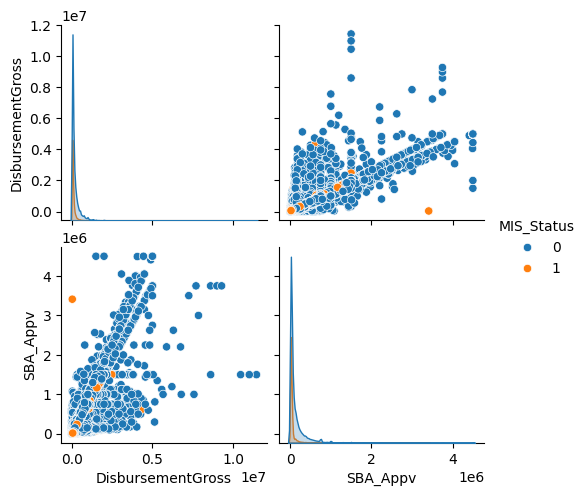

In [ ]:
# Create df with numeric and y
df = pd.concat([X_train, X_valid], axis=0)

# Add Y
df['MIS_Status'] = pd.concat([y_train, y_valid], axis=0)

# Keep only continuous variables
df = df[['MIS_Status', 'DisbursementGross', 'SBA_Appv']]

# Plotting
sns.pairplot(df, hue = 'MIS_Status' )
plt.show()

# Evaluate Performance

In [ ]:
# Classification Summary valid
classificationSummary(y_valid, da_reg_prior.predict(X_valid))

Confusion Matrix (Accuracy 0.4976)

       Prediction
Actual     0     1
     0 55415 91804
     1  3352 38841


Accuracy:  0.4976242265537558


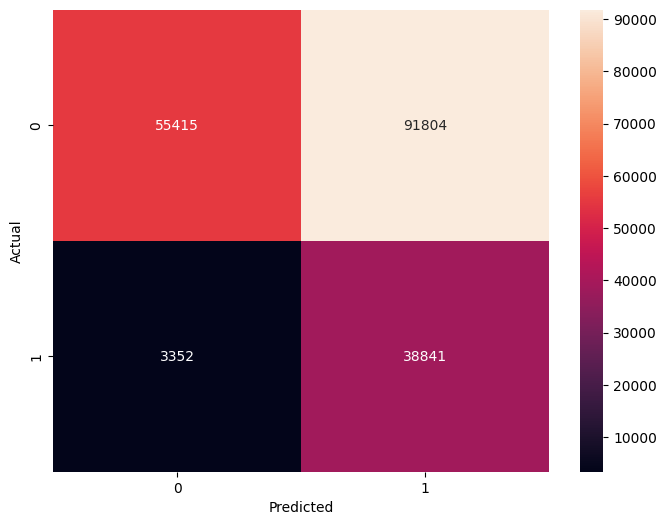

In [ ]:
#Confusion Matrix
y_pred = da_reg_prior.predict(X_valid)
confusion_matrix = pd.crosstab(y_valid, y_pred, rownames=['Actual'], colnames=['Predicted'])
plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix, annot=True, fmt='g')
print('Accuracy: ',metrics.accuracy_score(y_valid, y_pred))
plt.show()

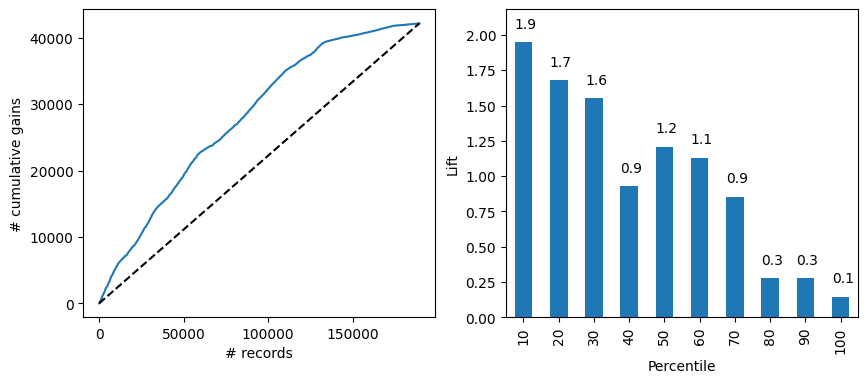

In [ ]:
# Lift and Decile Charts

# Step 1: Calculate predicted probabilities for the training set
valid_proba = da_reg_prior.predict_proba(X_valid)

# Step 2: Create a DataFrame with actual, predicted probabilities, and predicted labels for the training set
valid_result = pd.DataFrame({
    'actual': y_valid,
    'p(0)': [p[0] for p in valid_proba],
    'p(1)': [p[1] for p in valid_proba],
    'predicted': da_reg_prior.predict(X_valid)
})

# Step 3: Sort DataFrame by p(1)
valid_df = valid_result.sort_values(by=['p(1)'], ascending=False)

# Step 4: Plot Gains and Lift charts for the training set
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(10, 4))

gainsChart(valid_df.actual, ax=axes[0])
liftChart(valid_df.actual, title=False)

plt.show()

The model predicts 1.9 times better in the first decile.

In [ ]:
# Precision (Positive class is 'Acceptors')
precision = metrics.precision_score(y_valid, y_pred, pos_label=1)

# Recall (Sensitivity) or True Positive Rate
recall = metrics.recall_score(y_valid, y_pred, pos_label=1)

# F1 Score (harmonic mean of Precision and Recall)
f1 = metrics.f1_score(y_valid, y_pred, pos_label=1)


# Calculate the confusion matrix
cm = metrics.confusion_matrix(y_valid, y_pred)

# Extract True Negatives (TN), False Positives (FP), False Negatives (FN), True Positives (TP)
TN, FP, FN, TP = cm.ravel()

# Specificity (True Negative Rate)
specificity = TN / (TN + FP)

# Scores dataframe
scores = pd.DataFrame({
    'Model': ['Descriminant Analysis'],
    'Precision': [precision],
    'Recall': [recall],
    'F1 Score': [f1],
    'Specificity': [specificity]
})

scores

,Model,Precision,Recall,F1 Score,Specificity
0,Descriminant Analysis,0.297302,0.920556,0.44945,0.376412


The recall score is 92.05% which is very good.

In [ ]:
# Set up
disbursement_gross = np.array(X_train['DisbursementGross'])
actual_y = np.array(y_train)

# Get predicted probabilities for the positive class
pred_prob = da_reg_prior.predict_proba(X_train)[:, 1]  # Probabilities for class 1 ("Default")

# Initialize an array to store net profits for each threshold
thresholds = np.linspace(0.01, 0.99, 100)  # Range of thresholds from 0.01 to 0.99
net_profits = np.zeros_like(thresholds)

# Loop over each threshold and calculate the net profit
for i, threshold in enumerate(thresholds):
    # Classify based on the threshold
    pred_y = (pred_prob >= threshold).astype(int)

    # Calculate net profit based on the classification results (same logic as you provided)
    net_profit = np.zeros_like(actual_y, dtype=float)

    # Case 1: Correctly classified as "Paid in full" (Actual = 0, Predicted = 0)
    mask = (actual_y == 0) & (pred_y == 0)
    net_profit[mask] = 0.05 * disbursement_gross[mask]

    # Case 2: Incorrectly classified as "Paid in full" (Actual = 1, Predicted = 0)
    mask = (actual_y == 1) & (pred_y == 0)
    net_profit[mask] = -0.05 * disbursement_gross[mask] * 5

    # Case 3: Correctly classified as "Default" (Actual = 1, Predicted = 1)
    mask = (actual_y == 1) & (pred_y == 1)
    net_profit[mask] = 0

    # Case 4: Incorrectly classified as "Default" (Actual = 0, Predicted = 1)
    mask = (actual_y == 0) & (pred_y == 1)
    net_profit[mask] = 0  # No profit or loss for incorrect "default"

    # Calculate total net profit for this threshold
    net_profits[i] = np.sum(net_profit)

# Find the threshold that maximizes the net profit
best_threshold = thresholds[np.argmax(net_profits)]
max_net_profit = np.max(net_profits)

# Output the best threshold and corresponding net profit
print(f"Best Threshold: {best_threshold:.2f}")
print(f"Maximum Net Profit: {max_net_profit:,.2f} USD")

Best Threshold: 0.58
Maximum Net Profit: 963,153,018.95 USD


Given that the recall was high, the model finds the maximum profit of $963, 153, 018.95 at a cutoff value of 58%. The model is good at predicting 1s but not good at predicting 0s. This is why the net profit is not as large as the other models.